# 01 · Preprocessing — Ji et al. 2020 (cutaneous SCC, 10x)
Load malignant cells, threshold under-populated samples, select over-dispersed genes, **regress cell cycle** (the confound that obscures the developmental topology here), integrate samples with Harmony, embed, and annotate keratinocyte subtypes.

**Gate 1** is judged on the regenerated embedding: is the malignant structure sample-mixed and continuous?

In [1]:
import os, sys, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np
import pandas as pd
import scanpy as sc
import scanpy.external as sce
import scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1

In [2]:
# import custom 3CA dataloader (scripts live at the CCCA root, three levels up)
pth_ccca = os.path.abspath(os.path.join(os.getcwd(), '..', '..', '..'))
sys.path.append(pth_ccca)
from scripts.load import load_CCCA_adata

In [3]:
# paths — the Category/ partition puts this notebook two levels deeper than Puram,
# so the repo root is four levels up; strip the run suffix (-N) for the input folder
name = os.path.split(os.getcwd())[1]                 # Ji2020_Skin-6
cat  = os.path.split(os.path.split(os.getcwd())[0])[1] # Skin
dset = re.sub(r'-\d+$', '', name)                    # Ji2020_Skin
pth      = os.path.join(*(['..']*4))
pth_data = os.path.join(pth, 'data')
pth_in   = os.path.join(pth_data, 'unzip', 'CCCA', f'Data_{dset}')
pth_out  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig  = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_fig, exist_ok=True)

In [4]:
# load dataset -> select malignant cells
adata = load_CCCA_adata(pth_in)
adata = adata[adata.obs.celltype == 'Malignant'].copy(); adata

Loading ../../../../../../data/unzip/CCCA/Data_Ji2020_Skin
Done.


### Sample threshold — gap-finding
Sort per-sample malignant counts; the largest relative drop in the low tail marks the under-populated samples to drop.

In [5]:
n = adata.obs['sample'].value_counts()
print(n)
n_sorted = n.sort_values()
ratios = n_sorted.values[1:] / n_sorted.values[:-1]
gap_ix = int(np.argmax(ratios))
thr = int(np.sqrt(n_sorted.values[gap_ix] * n_sorted.values[gap_ix + 1]))
print(f'largest low-tail gap: {n_sorted.values[gap_ix]} -> {n_sorted.values[gap_ix+1]} '
      f'({ratios[gap_ix]:.1f}x); threshold ~ {thr}')

sample
P4     4216
P8     1472
P10    1130
P1     1064
P7     1012
P6      729
P2      640
P9      268
P5       40
P3       27
Name: count, dtype: int64
largest low-tail gap: 40 -> 268 (6.7x); threshold ~ 103


In [6]:
# keep samples above the gap (drops P3, P5)
keep = n.index[n >= thr]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print('kept', sorted(keep.tolist())); adata

kept ['P1', 'P10', 'P2', 'P4', 'P6', 'P7', 'P8', 'P9']


Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1443 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

over-dispersed: 1443


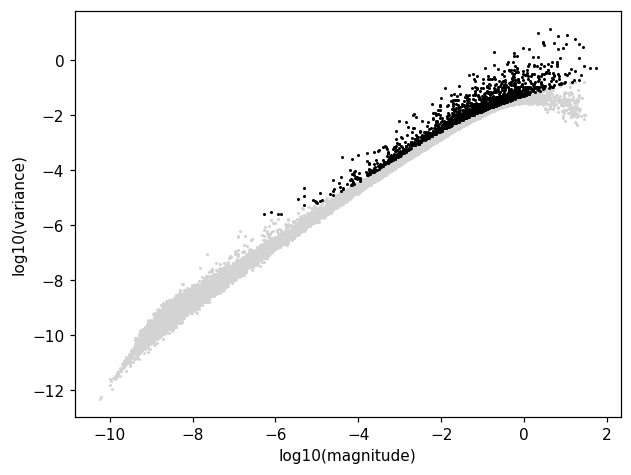

In [7]:
# filter genes + select over-dispersed features
sc.pp.filter_genes(adata, min_cells = 3)
adata.layers['lognorm'] = adata.X.copy()
scf.pp.find_overdispersed(adata, plot = True)
print('over-dispersed:', int(adata.var.highly_variable.sum()))

### Cell-cycle regression — the decisive re-derivation
cSCC keratinocytes carry a large proliferating compartment. Left in, the cell cycle forms its own axis and collapses the developmental topology (the published metadata already flags ~35% cycling cells). Score S/G2M de novo and regress them out of the over-dispersed matrix, so the embedding reflects lineage rather than proliferation.

In [8]:
s_genes = ['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL',
           'PRIM1','UHRF1','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2',
           'UBR7','POLD3','MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM',
           'CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
g2m_genes = ['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B',
             'MKI67','TMPO','CENPF','TACC3','FAM64A','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1',
             'KIF11','ANP32E','TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','HN1','CDC20','TTK','CDC25C',
             'KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA',
             'PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']
sg = [g for g in s_genes if g in adata.var_names]
g2 = [g for g in g2m_genes if g in adata.var_names]
sc.tl.score_genes_cell_cycle(adata, s_genes = sg, g2m_genes = g2)
print('phase:', adata.obs['phase'].value_counts().to_dict())

phase: {'G1': 5865, 'S': 2839, 'G2M': 1827}


In [9]:
# regress the cell cycle out of the over-dispersed matrix used for the embedding
hv = adata.var_names[adata.var.highly_variable]
emb = adata[:, hv].copy()
sc.pp.regress_out(emb, ['S_score', 'G2M_score'], n_jobs = 8)

In [10]:
# pca -> integrate samples (Harmony) — no sc.pp.scale (kept off; it segregates by patient here)
sc.pp.pca(emb, n_comps = 50)
sce.pp.harmony_integrate(emb, 'sample', theta = 2, max_iter_harmony = 20)
adata.obsm['X_pca'] = emb.obsm['X_pca']
adata.obsm['X_pca_harmony'] = emb.obsm['X_pca_harmony']

### Embedding + Gate 1
`n_pcs = 20` — the scree knee sits at ~6, but that under-powers the manifold (the Chen2020 precedent); 20 is the robust atlas scale. Read Gate 1 off the embedding: samples mixed, cell cycle dispersed, one continuous body.

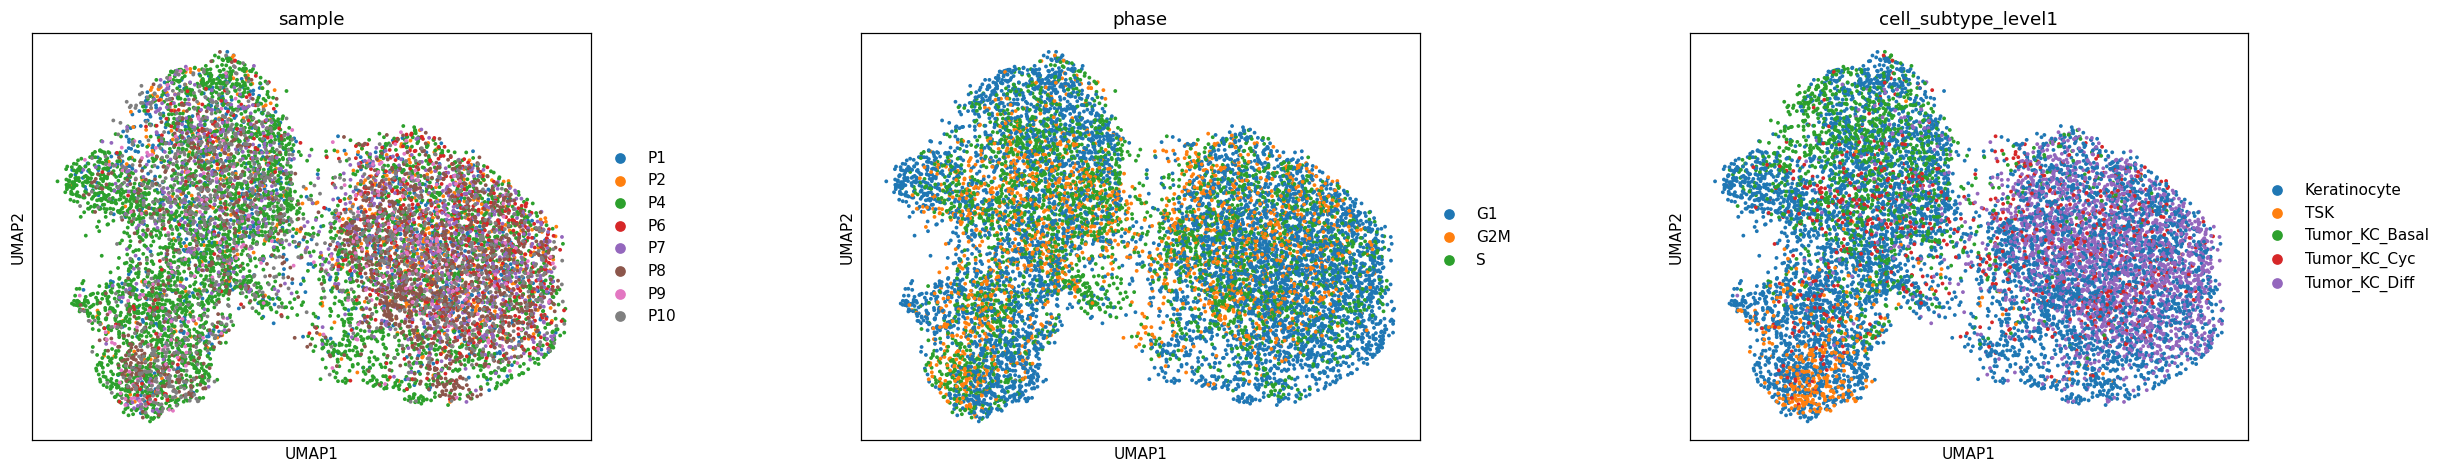

In [11]:
sc.pp.neighbors(adata, n_pcs = 20, n_neighbors = 30, use_rep = 'X_pca_harmony')
sc.tl.umap(adata, spread = 1.3, random_state = 0)
sc.pl.umap(adata, color = ['sample', 'phase', 'cell_subtype_level1'], size = 25, wspace = 0.35)

Samples interleave across the whole body and the cell-cycle phases are dispersed (not a lobe) — the regression worked. The published Ji subtypes lay down an ordered geography: a basal/keratinocyte core, a differentiating pole, and a TSK (tumor-specific keratinocyte, leading-edge) tail.

In [12]:
# cluster -> check for detached islands via a UMAP radius graph (connected components)
from sklearn.neighbors import radius_neighbors_graph
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree
X = adata.obsm['X_umap']
d, _ = cKDTree(X).query(X, k = 2)
r = 6 * np.median(d[:, 1])
G = radius_neighbors_graph(X, radius = r)
ncomp, lab = connected_components(G, directed = False)
sizes = pd.Series(lab).value_counts()
print(f'radius-graph components: {ncomp}; largest = {sizes.iloc[0]} / {adata.n_obs} '
      f'({100*sizes.iloc[0]/adata.n_obs:.1f}%)')

radius-graph components: 9; largest = 10523 / 10531 (99.9%)


In [13]:
# keep the largest connected component (no detached islands of note here)
keep_lab = sizes.index[0]
adata = adata[lab == keep_lab].copy()
print('after island removal:', adata.n_obs)

after island removal: 10523


### Subtype annotation — data markers + Ji et al. 2020 published calls
Leiden at low resolution resolves three states; label each by its top keratinocyte marker program and confirm against Ji's reported subtypes (Tumor_KC_Basal / _Diff / TSK).

In [14]:
sc.tl.leiden(adata, resolution = 0.3, random_state = 0)
prog = {'Basal': ['KRT14','KRT5','TP63','COL17A1'],
        'Differentiating': ['KRT1','KRT10','SPRR1B','FLG'],
        'TSK': ['MMP10','MMP1','LAMC2','PTHLH','FN1']}
sig = pd.DataFrame({k: adata[:, [g for g in v if g in adata.var_names]].X.toarray().mean(1)
                    for k, v in prog.items()}, index = adata.obs_names)
sig['leiden'] = adata.obs.leiden.values
means = sig.groupby('leiden').mean()
print(means.round(2))
print()
print(pd.crosstab(adata.obs.leiden, adata.obs.cell_subtype_level1))

        Basal  Differentiating   TSK
leiden                              
0        2.59             1.29  0.04
1        3.06             0.42  0.08
2        3.08             0.45  0.48

cell_subtype_level1  Keratinocyte  TSK  ...  Tumor_KC_Cyc  Tumor_KC_Diff
leiden                                  ...                             
0                            2410   16  ...           446           2177
1                            2169   13  ...           257            147
2                            1104  291  ...            82             19

[3 rows x 5 columns]


relative enrichment (z):
        Basal  Differentiating   TSK
leiden                              
0       -1.15             1.15 -0.66
1        0.54            -0.60 -0.49
2        0.61            -0.55  1.15
cluster -> label: {'0': 'Differentiating', '1': 'Basal', '2': 'TSK'}


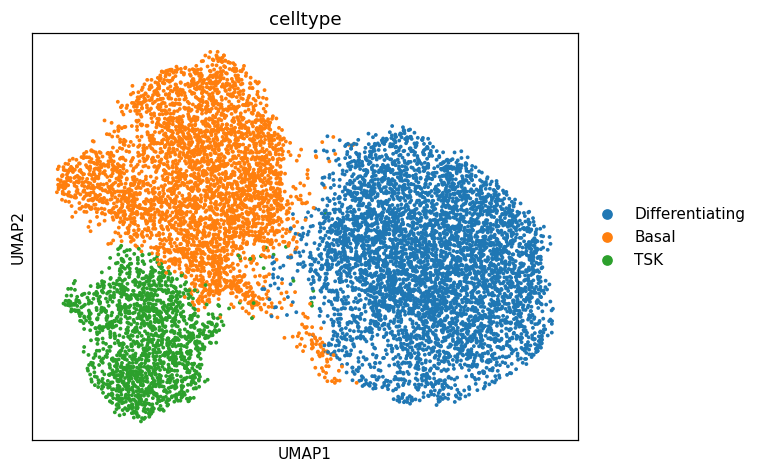

In [15]:
# assign each Leiden cluster to its most ENRICHED program (z-score across clusters,
# since basal keratins are high everywhere in absolute terms)
z = (means - means.mean()) / means.std()
label = z.idxmax(axis = 1).to_dict()
print('relative enrichment (z):'); print(z.round(2))
print('cluster -> label:', label)
adata.obs['celltype'] = adata.obs.leiden.map(label).astype('category')
sc.pl.umap(adata, color = 'celltype', size = 25)

In [16]:
# save processed data to h5ad file
adata.X = adata.layers['lognorm'].copy()   # carry log-normalized expression for scoring
del adata.layers['lognorm']
adata.write(os.path.join(pth_out, 'processed.h5ad')); adata

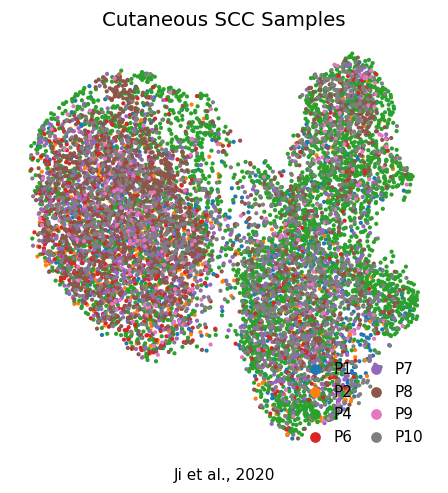

In [17]:
# save sample integration figure
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 'sample', size = 30, frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, ncol = 2, frameon = False, loc = 'lower right',
          columnspacing = .5, handletextpad = .25)
ax.set_title('Cutaneous SCC Samples', size = 13)
ax.text(.5, -.05, 'Ji et al., 2020', ha = 'center', transform = ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches = 'tight')